# **Datos faltantes e imputación múltiple**

Este cuaderno complementa el análisis exploratorio (`eda.ipynb`) y los modelos jerárquicos (`fit_models.ipynb`, `model_comparison.ipynb`). Allí los modelos se ajustan con *listwise deletion* (N = 530). Aquí se diagnostica el mecanismo de los faltantes, se imputan con PMM y se repiten **los mismos modelos** sobre los datos imputados, para comprobar que las conclusiones no dependen de cómo se tratan los faltantes.

## *Carga de paquetes y configuración*

In [1]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(gt)
  library(effectsize)
})

# Evita que VS Code intente dibujar las tablas en LaTeX
options(jupyter.display_mimetypes = c("text/plain", "text/html", "image/png", "image/jpeg", "image/svg+xml"))

# Parche para que las tablas gt se vean en Jupyter (mismo del EDA)
repr_html.gt_tbl <- function(obj, ...) gt::as_raw_html(obj)
repr_markdown.gt_tbl <- function(obj, ...) NULL
repr_latex.gt_tbl <- function(obj, ...) NULL
for (g in c("repr_html", "repr_markdown", "repr_latex")) {
  registerS3method(g, "gt_tbl", get(paste0(g, ".gt_tbl")), envir = asNamespace("repr"))
}

# Las rutas de config.R son relativas a la raíz del proyecto.
if (!file.exists("myst.yml") && file.exists("../myst.yml")) setwd("..")
if (file.exists(".Renviron")) readRenviron(".Renviron")

# Mismas fuentes que fit_models.ipynb: así los modelos son idénticos
source("R/config.R")
source("R/data_prep.R")
source("R/moderation_pipeline.R")
source("R/cross_validation.R")
source("R/elastic_net.R")

fmt_p <- function(x) ifelse(x < 0.001, "< .001", sub("^0", "", sprintf("%.3f", x)))

theme_set(theme_minimal(base_size = 12) +
            theme(plot.title = element_text(hjust = 0.5),
                  plot.subtitle = element_text(hjust = 0.5)))

apoyo_vars <- SUPPORT_VARS
getwd()

[1] "/workspaces/social-support-entrapment-gender-atlantico"

In [2]:
# Datos crudos (680 estudiantes); mismos criterios de faltante que el EDA
ruta_datos <- Sys.getenv("DATA_PATH", unset = "data/df_moderation_2026.csv")

datos <- read_csv(ruta_datos, show_col_types = FALSE) %>%
  mutate(across(where(is.character), ~ na_if(na_if(., ""), "Missing")))

stopifnot(is.data.frame(datos), nrow(datos) == 680)
dim(datos)

[1] 680  12

## *Mecanismos de datos faltantes*

La literatura distingue tres mecanismos (Rubin, 1976):

- **MCAR** (*Missing Completely At Random*): la probabilidad de que falte un dato no depende de ninguna variable, observada o no. Es el supuesto más fuerte y raramente se sostiene.
- **MAR** (*Missing At Random*): la probabilidad de que falte un dato depende de variables **observadas**, pero no del valor faltante en sí. Es el supuesto bajo el cual funciona la imputación múltiple.
- **MNAR** (*Missing Not At Random*): la probabilidad de que falte depende del propio valor faltante (por ejemplo, que no respondan quienes tienen más entrapment). **No se puede verificar con los datos**: solo se argumenta con conocimiento del contexto y se evalúa con análisis de sensibilidad.

MAR y MNAR no se distinguen con una prueba estadística. Lo que sí se puede hacer es descartar MCAR y ver de qué variables observadas depende el faltante, para incluirlas en el modelo de imputación.

### *Prueba MCAR de Little*

La prueba de Little (1988) contrasta la hipótesis nula de que los datos son MCAR: compara las medias de las variables entre los distintos patrones de faltantes. Un p-valor pequeño rechaza MCAR; uno grande **no demuestra** MCAR, solo indica falta de evidencia en contra. Además, solo admite variables numéricas y tiene poca potencia cuando hay muchas variables, por lo que se complementa con comparaciones entre estudiantes con y sin dato.

In [3]:
if (!requireNamespace("naniar", quietly = TRUE))
  install.packages("naniar", repos = "https://cloud.r-project.org")
library(naniar)

vars_mcar <- c("Family", "Friends", "SigOthers", "Entrapment", "Age")
print(mcar_test(datos[, vars_mcar]))

Installing package into ‘/opt/renv/library/R-4.3/x86_64-pc-linux-gnu’
(as ‘lib’ is unspecified)



also installing the dependencies ‘gridExtra’, ‘plyr’, ‘norm’, ‘visdat’, ‘viridis’, ‘UpSetR’




# A tibble: 1 × 4
  statistic    df p.value missing.patterns
      <dbl> <dbl>   <dbl>            <int>
1      9.67    15   0.840                8


La prueba de Little no rechazó la hipótesis de datos faltantes completamente al azar (χ²(15) = 9.67, p = .84; 8 patrones de faltantes). Este resultado indica que no hay evidencia de que el faltante dependa de la edad, el apoyo social o el entrapment, pero no demuestra MCAR: un p-valor alto solo señala falta de evidencia en contra, y la prueba no evalúa las variables categóricas ni puede descartar un mecanismo MNAR. Por ello se complementa con la comparación de estudiantes con y sin dato según las covariables sociodemográficas, que sí muestra una dependencia del municipio.

### *Faltantes según las demás covariables*

Se crea un indicador de faltante (apoyo social y entrapment) y se contrasta con cada covariable mediante $\chi^2$ (con simulación de Monte Carlo cuando alguna frecuencia esperada es menor que 5) y, para la edad, Wilcoxon. El p se ajusta por Holm dentro de cada indicador.

In [4]:
set.seed(SEED)

faltantes_apoyo <- rowSums(is.na(datos[apoyo_vars]))

df_mis <- datos %>%
  mutate(falta_apoyo      = factor(if_else(faltantes_apoyo > 0, "Falta", "Completo")),
         falta_entrapment = factor(if_else(is.na(Entrapment), "Falta", "Completo")))

cov_cat <- c("Gender", "Municipality", "Grade", "Ethnicity", "SSE", "Education")

prueba_falta <- function(ind) {
  g <- df_mis[[ind]]

  cat <- map_dfr(cov_cat, function(v) {
    x   <- as.character(df_mis[[v]])
    tab <- table(g[!is.na(x)], x[!is.na(x)])
    mc  <- any(suppressWarnings(chisq.test(tab)$expected) < 5)
    ji  <- suppressWarnings(chisq.test(tab, simulate.p.value = mc, B = 10000))
    tibble(Covariable = v,
           Prueba = if (mc) "χ² (Monte Carlo)" else "χ²",
           p = ji$p.value,
           V = cramers_v(tab, adjust = FALSE)$Cramers_v)
  })

  edad <- tibble(Covariable = "Age", Prueba = "Wilcoxon",
                 p = wilcox.test(Age ~ g, data = df_mis)$p.value,
                 V = NA_real_)

  bind_rows(cat, edad) %>% mutate(p_holm = p.adjust(p, method = "holm"))
}

res_falta <- map_dfr(c(`Falta apoyo social` = "falta_apoyo",
                       `Falta entrapment`   = "falta_entrapment"),
                     prueba_falta, .id = "Indicador")

res_falta %>%
  gt(groupname_col = "Indicador") %>%
  fmt_number(V, decimals = 3) %>%
  fmt(columns = c(p, p_holm), fns = fmt_p) %>%
  sub_missing(columns = V, missing_text = "—") %>%
  cols_label(p_holm = "p (Holm)", V = "V de Cramér") %>%
  tab_header(title = "Faltantes según las covariables")

<div id="hqcvpwigwz" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#hqcvpwigwz table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#hqcvpwigwz thead, #hqcvpwigwz tbody, #hqcvpwigwz tfoot, #hqcvpwigwz tr, #hqcvpwigwz td, #hqcvpwigwz th {
  border-style: none;
}

#hqcvpwigwz p {
  margin: 0;
  padding: 0;
}

#hqcvpwigwz .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#hqcvpwigwz .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#hqcvpwigwz .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#hqcvpwigwz .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#hqcvpwigwz .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#hqcvpwigwz .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#hqcvpwigwz .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#hqcvpwigwz .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#hqcvpwigwz .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#hqcvpwigwz .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#hqcvpwigwz .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#hqcvpwigwz .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#hqcvpwigwz .gt_spanner_row {
  border-bottom-style: hidden;
}

#hqcvpwigwz .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

La falta de datos se asocia con el municipio, tanto en apoyo social (V = 0.17; p Holm = .007) como en entrapment (V = 0.29; p Holm < .001), pero no con el género, el grado, el nivel socioeconómico, el nivel educativo de los padres ni la edad. La asociación se concentra en Suan, donde falta el 28.0 % (7 de 25) del apoyo social y del entrapment, frente a 2.7–7.1 % y 1.4–2.3 % en los demás municipios. La etnia mostró una asociación marginal con la falta de apoyo (p = .035) que no se sostiene tras la corrección de Holm (p = .210). Este patrón es incompatible con un mecanismo completamente al azar (MCAR) y es coherente con MAR condicionado al municipio, por lo que esta variable se incluye en el modelo de imputación.

### *Faltantes por municipio*

In [5]:
df_mis %>%
  group_by(Municipality) %>%
  summarise(n = n(),
            sin_apoyo = sum(falta_apoyo == "Falta"),
            pct_apoyo = round(100 * sin_apoyo / n, 1),
            sin_entrapment = sum(falta_entrapment == "Falta"),
            pct_entrapment = round(100 * sin_entrapment / n, 1),
            sin_genero = sum(is.na(Gender)),
            .groups = "drop") %>%
  gt() %>%
  tab_header(title = "Faltantes por municipio")

<div id="wgbtnlnhrs" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#wgbtnlnhrs table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#wgbtnlnhrs thead, #wgbtnlnhrs tbody, #wgbtnlnhrs tfoot, #wgbtnlnhrs tr, #wgbtnlnhrs td, #wgbtnlnhrs th {
  border-style: none;
}

#wgbtnlnhrs p {
  margin: 0;
  padding: 0;
}

#wgbtnlnhrs .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#wgbtnlnhrs .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#wgbtnlnhrs .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#wgbtnlnhrs .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#wgbtnlnhrs .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#wgbtnlnhrs .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#wgbtnlnhrs .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#wgbtnlnhrs .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#wgbtnlnhrs .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#wgbtnlnhrs .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#wgbtnlnhrs .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#wgbtnlnhrs .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#wgbtnlnhrs .gt_spanner_row {
  border-bottom-style: hidden;
}

#wgbtnlnhrs .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

In [6]:
# Patrones de faltantes dentro de Suan
df_mis %>%
  dplyr::filter(Municipality == "Suan") %>%
  mutate(sin_genero = is.na(Gender)) %>%
  count(falta_apoyo, falta_entrapment, sin_genero)

falta_apoyo,falta_entrapment,sin_genero,n
<fct>,<fct>,<lgl>,<int>
Completo,Completo,FALSE,13
Completo,Falta,TRUE,5
Falta,Completo,FALSE,5
Falta,Falta,TRUE,2


En Suan (n = 25), solo 13 estudiantes tienen completos el apoyo social, el entrapment y el género; 5 carecen únicamente del apoyo, 5 carecen del entrapment y del género, y 2 carecen de los tres. Dado que solo 2 casos carecen de todo, la imputación dispone de información observada para la mayoría de los estudiantes de ese municipio. Aun así, por el tamaño reducido de Suan (3.7 % de la muestra), los resultados finales se contrastarán con un análisis de sensibilidad que excluya este municipio.

## *Qué estudiantes entran a los modelos*

Los modelos del pipeline (`COVARIATE_VARS`: municipio, nivel socioeconómico y etnia) con *listwise deletion* conservan 530 de 680 estudiantes. La pérdida no es pareja: en Suan se conservan solo 13 de 25. La imputación recupera esa información.

In [7]:
cat("Covariables del pipeline:", paste(COVARIATE_VARS, collapse = ", "), "\n")

model_data <- run_data_prep()   # los 530 casos completos del pipeline

datos %>%
  count(Municipality, name = "Crudo (N = 680)") %>%
  left_join(model_data %>% count(Municipality, name = "Listwise (N = 530)"), by = "Municipality") %>%
  mutate(`% conservado` = round(100 * `Listwise (N = 530)` / `Crudo (N = 680)`, 1)) %>%
  gt() %>%
  tab_header(title = "Estudiantes por municipio: datos crudos frente a listwise")

Covariables del pipeline: Municipality, SSE, Ethnicity 


Filas crudas:          680
Muestra analitica:     530 (listwise sobre Entrapment, Family, Friends, SigOthers, Gender, Municipality, SSE, Ethnicity)
Niveles de referencia: SSE = Low | Ethnicity = Mestizo | Municipality = Polo Nuevo
Grandes medias:        Family = 0.030437 | Friends = 0.032544 | SigOthers = 0.045578
Codificacion genero:   dummy (Female = 0, Male = 1)
Escrito: data/df_modeling_2026.csv


<div id="yafmoldpel" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#yafmoldpel table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#yafmoldpel thead, #yafmoldpel tbody, #yafmoldpel tfoot, #yafmoldpel tr, #yafmoldpel td, #yafmoldpel th {
  border-style: none;
}

#yafmoldpel p {
  margin: 0;
  padding: 0;
}

#yafmoldpel .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#yafmoldpel .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#yafmoldpel .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#yafmoldpel .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#yafmoldpel .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#yafmoldpel .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#yafmoldpel .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#yafmoldpel .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#yafmoldpel .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#yafmoldpel .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#yafmoldpel .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#yafmoldpel .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#yafmoldpel .gt_spanner_row {
  border-bottom-style: hidden;
}

#yafmoldpel .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Imputación múltiple*

Imputar una sola vez (imputación simple) trata el valor rellenado como si fuera un dato real, lo que subestima los errores estándar y produce intervalos de confianza demasiado estrechos. La **imputación múltiple** (Rubin, 1987) genera *m* bases completas, cada una con valores imputados distintos, y luego:

1. se ajusta el mismo modelo en cada una de las *m* bases;
2. se combinan los resultados con las **reglas de Rubin**: el coeficiente final es el promedio de los *m* coeficientes y su varianza suma la variabilidad dentro de cada base y la variabilidad entre bases (la incertidumbre por no conocer el dato real).

Se usa `m = 20`: la recomendación de White, Royston y Wood (2011) es que *m* sea al menos igual al porcentaje de casos incompletos, que aquí es 18.2 %.

### *Predictive Mean Matching (PMM)*

PMM (Little, 1988; van Buuren, 2018) imputa un valor **realmente observado** tomado de un estudiante con un perfil similar, en lugar de generar uno con una fórmula. Para cada caso faltante:

1. se ajusta una regresión con los casos observados y se toma una extracción aleatoria de sus coeficientes (para reflejar la incertidumbre de la estimación);
2. se calcula la distancia entre la predicción del caso faltante y la de cada caso observado;
3. se arma un grupo de *d* donantes con las predicciones más cercanas (`donors = 5`; se recomienda entre 3 y 10);
4. se elige un donante al azar del grupo y se copia su valor observado.

Las imputaciones siempre quedan dentro del rango de los puntajes reales y el método es robusto a desviaciones de la normalidad, como el efecto piso visto en el análisis univariado. Limitación: funciona mejor con muestras grandes y no corrige un modelo de imputación mal especificado.

### *Diseño de la imputación*

Como la pregunta de investigación es la **moderación por género**, el modelo de imputación debe permitir que las relaciones entre las variables difieran entre mujeres y hombres. Un modelo de imputación sin interacciones tiende a atenuar una interacción real hacia cero. Por eso se **imputa por separado en cada género** (imputación estratificada), lo que equivale a un modelo de imputación con todas las interacciones con el género y es compatible con los modelos M3.

- Los 11 estudiantes sin género tampoco tienen entrapment, de modo que no aportan información sobre la relación entre apoyo y entrapment: quedan fuera, y cada base imputada tiene 669 estudiantes.
- Variables en el modelo de imputación: las del análisis (municipio, SSE, etnia, tres dimensiones de apoyo, entrapment) más la edad como auxiliar. El municipio se incluye porque el faltante depende de él.
- SSE se colapsa con el mismo mapa del pipeline (`SSE_COLLAPSE_MAP`), y la edad se reserva como análisis de sensibilidad.
- `Entrapment_SE` no se incluye porque es el error de medición del puntaje, no una característica del estudiante.
- Variables continuas: PMM; categóricas: regresión logística o politómica (`mice`, van Buuren y Groothuis-Oudshoorn, 2011).

In [8]:
if (!requireNamespace("mice", quietly = TRUE))
  install.packages("mice", repos = "https://cloud.r-project.org")
library(mice)

M_IMP <- 20
vars_imp <- c("Municipality", "SSE", "Ethnicity", "Age", "Family", "Friends", "SigOthers", "Entrapment")
stopifnot(all(COVARIATE_VARS %in% vars_imp))

esquema_gen <- unlist(GENDER_CODING_SCHEMES[[GENDER_CODING]])   # Female = 0, Male = 1

d_imp <- datos %>%
  dplyr::filter(Gender %in% names(esquema_gen)) %>%
  mutate(SSE          = factor(unname(unlist(SSE_COLLAPSE_MAP)[as.character(SSE)])),
         Municipality = factor(Municipality),
         Ethnicity    = factor(Ethnicity)) %>%
  dplyr::select(Gender, all_of(vars_imp))

cat("Estudiantes con género:", nrow(d_imp), "\n")
table(d_imp$Gender)
table(d_imp$SSE, useNA = "ifany")

Installing package into ‘/opt/renv/library/R-4.3/x86_64-pc-linux-gnu’
(as ‘lib’ is unspecified)



also installing the dependencies ‘ucminf’, ‘ordinal’, ‘pan’, ‘jomo’, ‘mitml’





Attaching package: ‘mice’




The following object is masked from ‘package:stats’:

    filter




The following objects are masked from ‘package:base’:

    cbind, rbind




Estudiantes con género: 669 



Female   Male 
   372    297 


        Low Medium-High        <NA> 
        490         117          62 

In [9]:
imputar_estrato <- function(d, semilla) {
  d <- d %>% dplyr::select(-Gender)
  ini <- mice(d, maxit = 0)
  mice(d, m = M_IMP, maxit = 20, method = ini$method, donors = 5,
       printFlag = FALSE, seed = semilla)
}

imp_f <- imputar_estrato(dplyr::filter(d_imp, Gender == "Female"), SEED)
imp_m <- imputar_estrato(dplyr::filter(d_imp, Gender == "Male"),   SEED + 1)

imp_f$method
imp_f$loggedEvents   
imp_m$loggedEvents

Municipality          SSE    Ethnicity          Age       Family      Friends 
          ""     "logreg"    "polyreg"        "pmm"        "pmm"        "pmm" 
   SigOthers   Entrapment 
       "pmm"        "pmm"

NULL

NULL

Los métodos asignados son PMM para las variables continuas, regresión logística para SSE (dos niveles) y regresión politómica para municipio y etnia; las variables sin faltantes no se imputan.

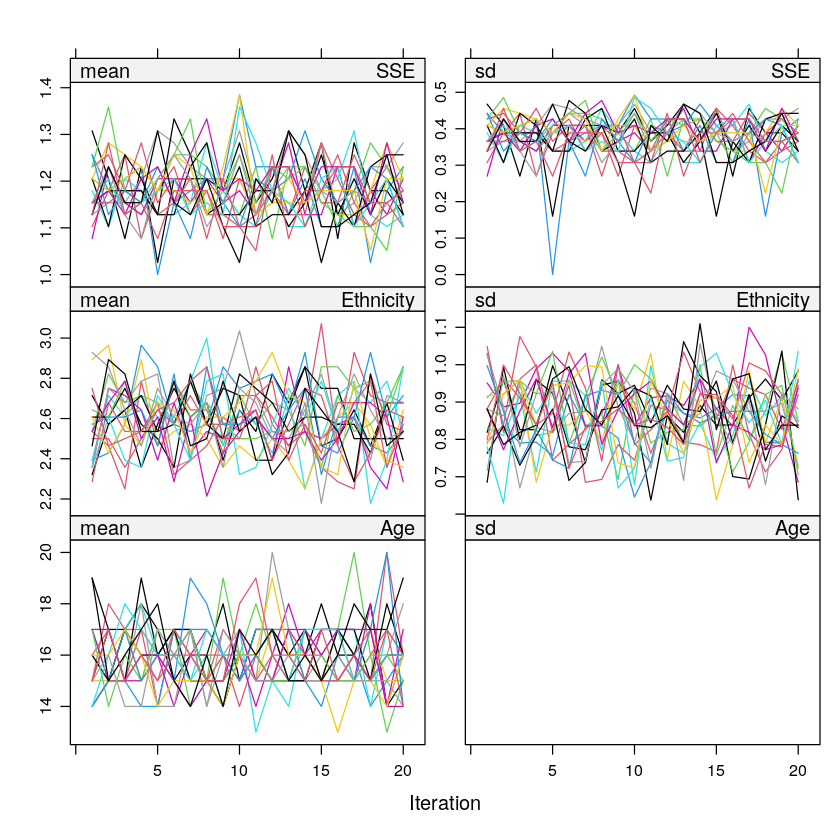

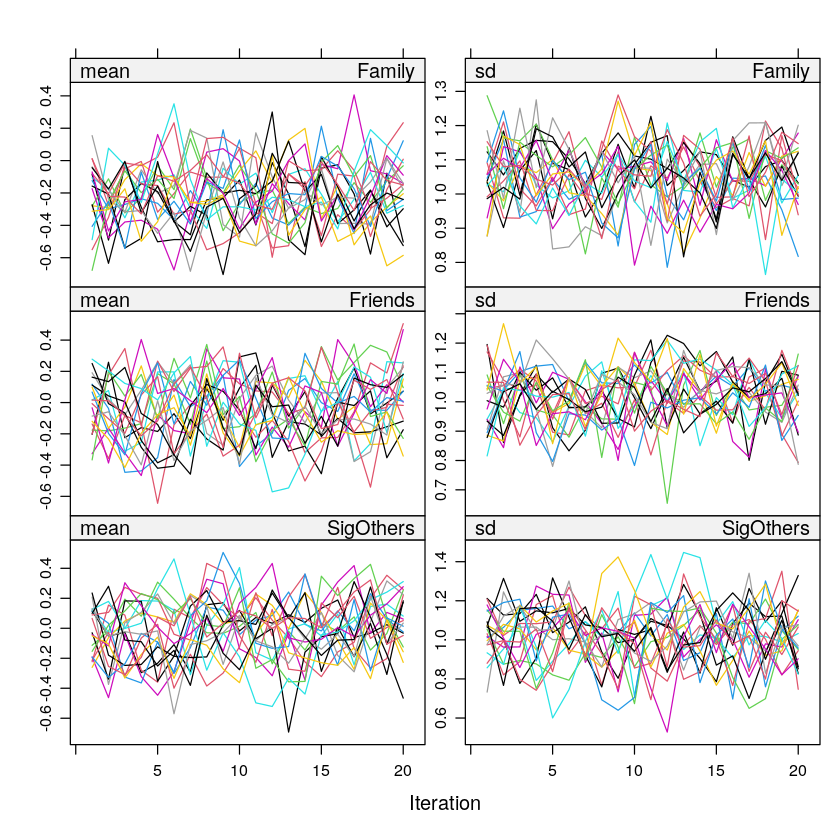

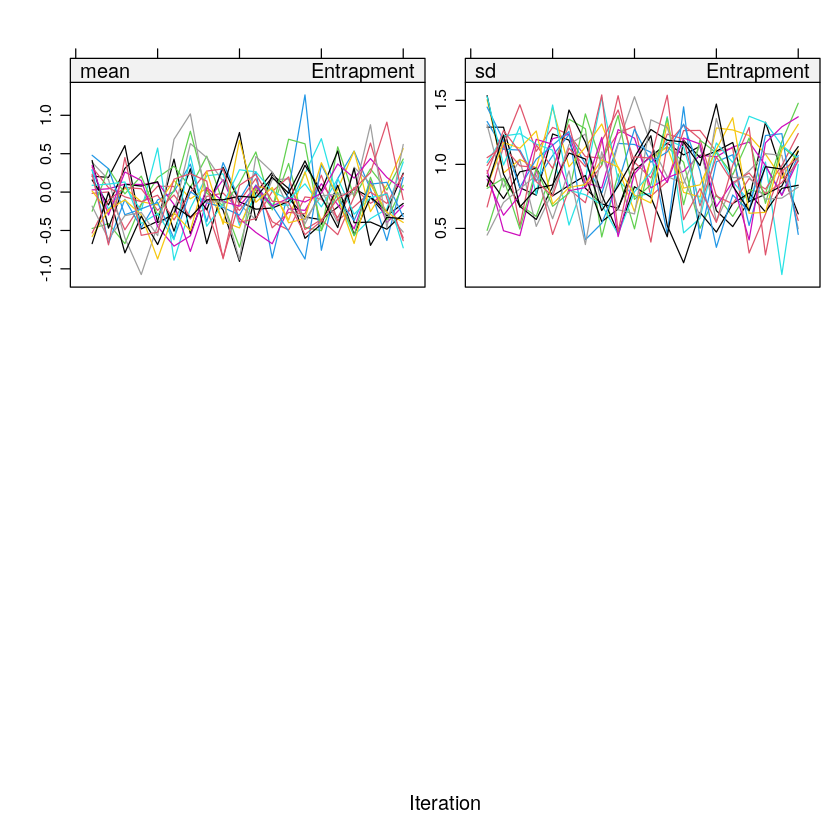

In [10]:
plot(imp_f)  

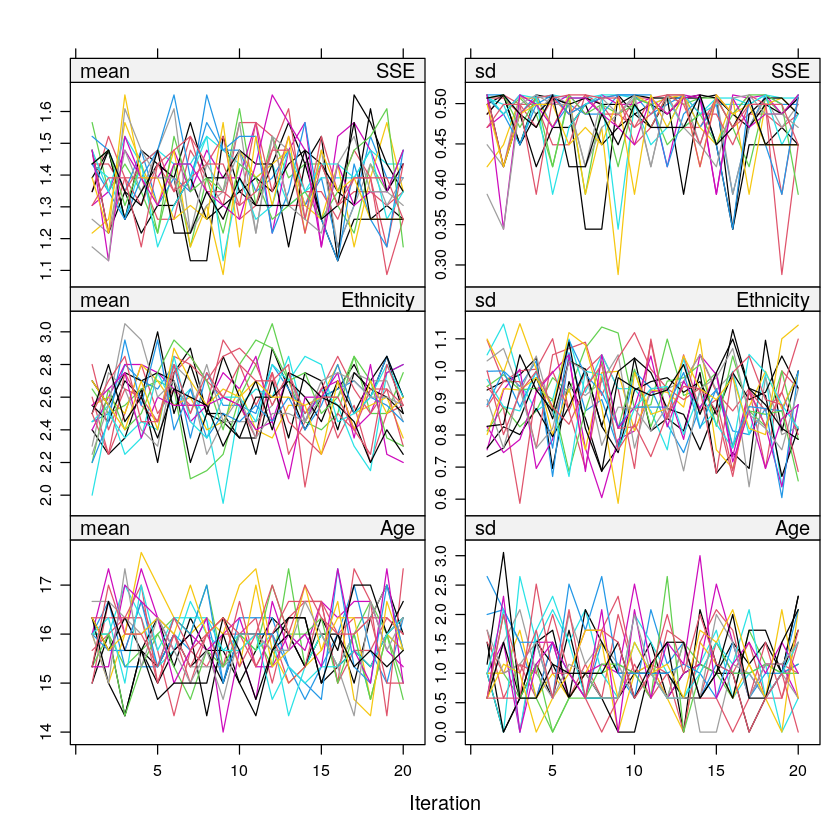

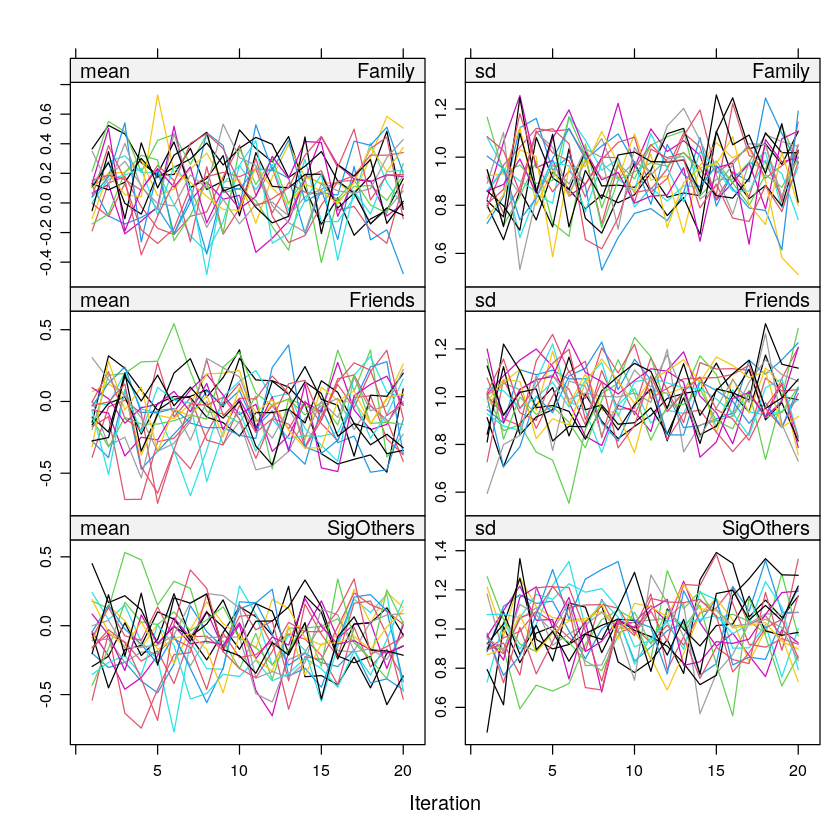

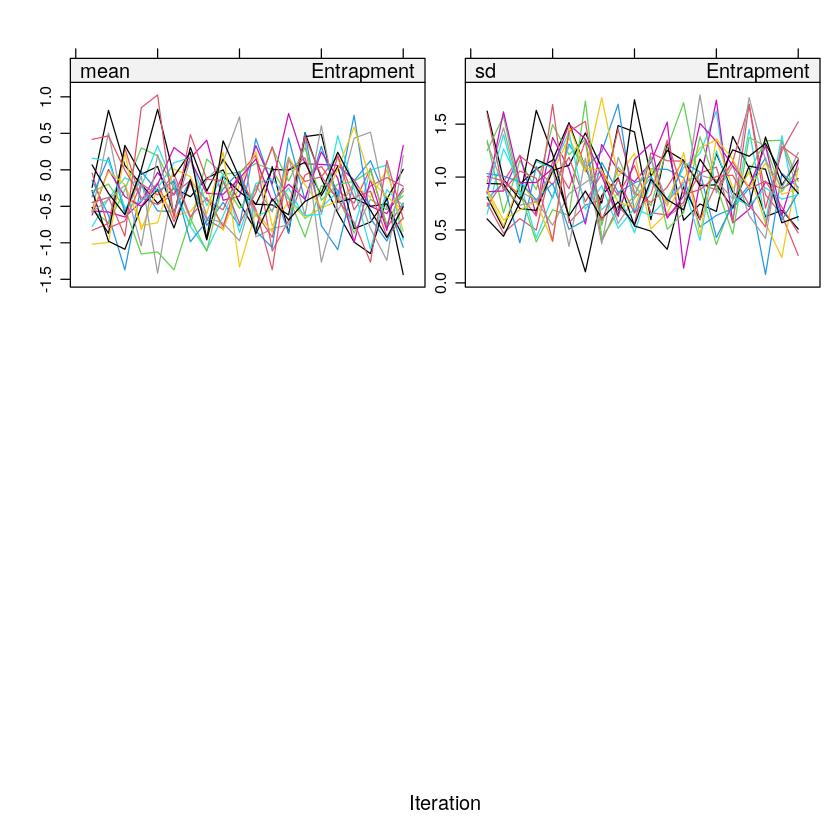

In [11]:
plot(imp_m)   

Las 20 cadenas de cada variable se mezclan sin tendencia a lo largo de las 20 iteraciones en ambos géneros, lo que indica convergencia. Las oscilaciones de `Entrapment` reflejan el reducido número de valores imputados, no un problema de convergencia.

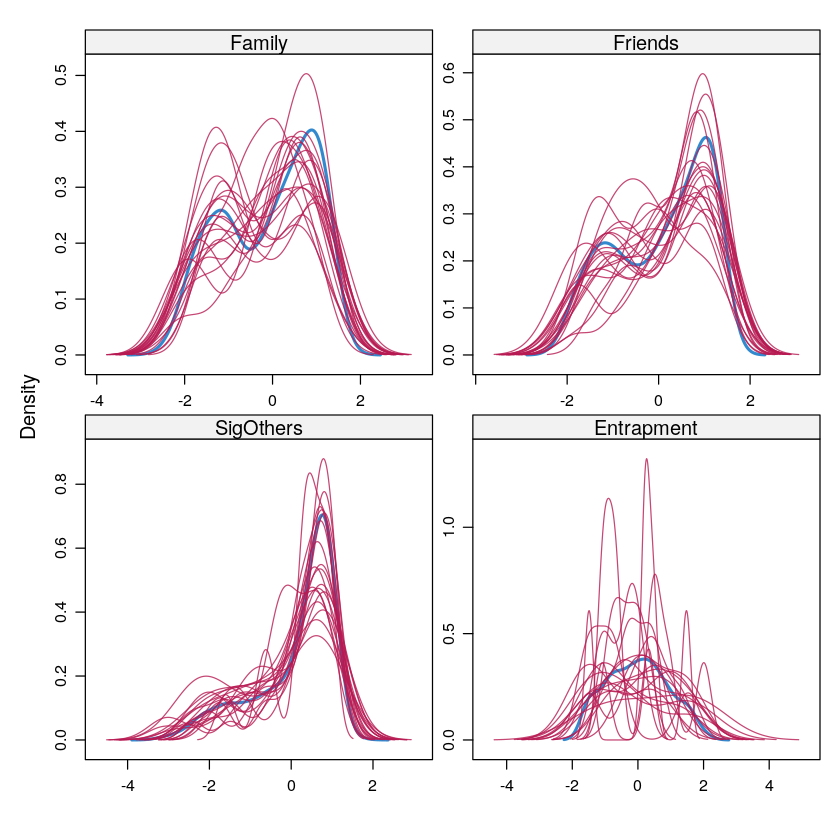

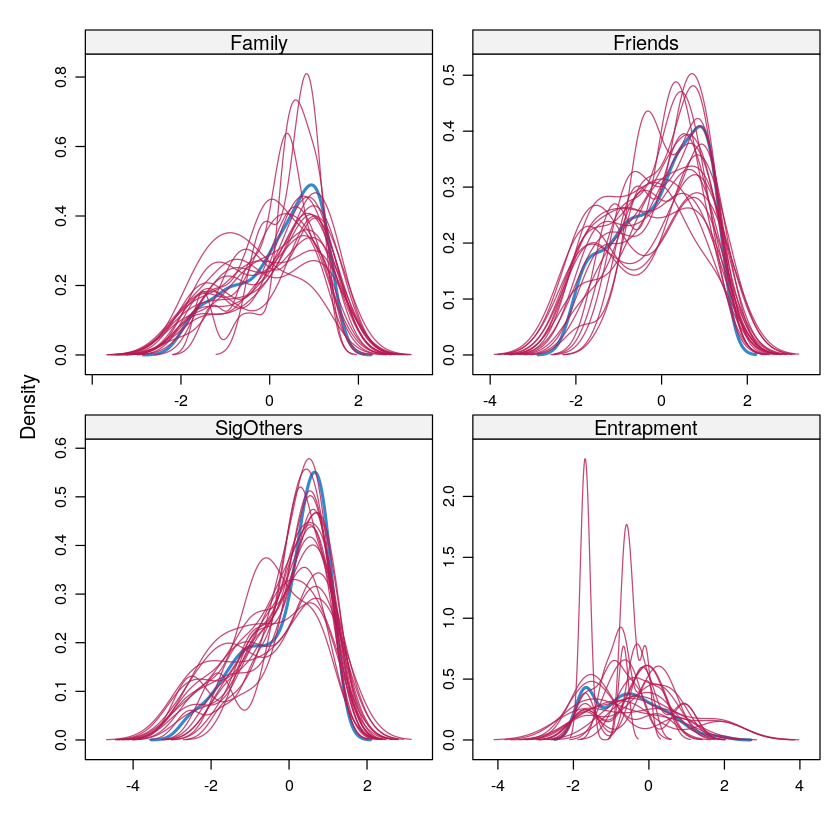

In [12]:

densityplot(imp_f, ~ Family + Friends + SigOthers + Entrapment)
densityplot(imp_m, ~ Family + Friends + SigOthers + Entrapment)

Las distribuciones imputadas de las tres dimensiones de apoyo social siguen la forma y el rango de las observadas en ambos géneros, sin valores fuera de rango, con la dispersión esperable por el reducido número de valores imputados en cada estrato. En `Entrapment` las curvas imputadas son más irregulares y presentan picos, porque solo se imputan 9 valores (los 11 estudiantes sin género, que tampoco tienen entrapment, quedan fuera); al ser PMM, los valores imputados se toman de valores realmente observados, por lo que reproducen incluso el efecto piso del entrapment.

## *Modelos sobre los datos imputados*

Se reconstruye cada base imputada con el mismo preprocesamiento del pipeline: género codificado con `GENDER_CODING`, niveles de referencia de `REFERENCE_LEVELS` y las tres dimensiones de apoyo centradas con las mismas grandes medias de los 530 casos (así el intercepto y el efecto del género son comparables). Los modelos usan `build_formulas()`, es decir, las mismas 10 fórmulas.

In [13]:
centros <- map_dbl(set_names(SUPPORT_VARS), ~ mean(model_data[[.x]]))
centros

armar_base <- function(i) {
  d <- bind_rows(mice::complete(imp_f, i) %>% mutate(Gender = "Female"),
                 mice::complete(imp_m, i) %>% mutate(Gender = "Male"))

  d$Gender_code  <- unname(esquema_gen[d$Gender])
  d$Municipality <- fct_infreq(factor(d$Municipality))                 # referencia: la más frecuente
  d$SSE          <- fct_relevel(factor(d$SSE), REFERENCE_LEVELS$SSE)
  d$Ethnicity    <- fct_relevel(factor(d$Ethnicity), REFERENCE_LEVELS$Ethnicity)
  for (v in SUPPORT_VARS) d[[paste0(v, "_c")]] <- d[[v]] - centros[[v]]
  d
}

bases <- map(seq_len(M_IMP), armar_base)

stopifnot(all(map_int(bases, ~ sum(!complete.cases(.x[c("Entrapment", "Gender_code", COVARIATE_VARS,
                                                         paste0(SUPPORT_VARS, "_c"))]))) == 0))
cat("Bases imputadas:", length(bases), "| estudiantes por base:", nrow(bases[[1]]), "\n")
bases[[1]] %>% count(Municipality)

Family    Friends  SigOthers 
0.03043702 0.03254436 0.04557778

Bases imputadas: 20 | estudiantes por base: 669 


Municipality,n
<fct>,<int>
Polo Nuevo,350
Santo Tomas,227
Puerto Colombia,74
Suan,18


In [14]:
formulas <- build_formulas()
ajustar  <- function(f, lista = bases) as.mira(map(lista, ~ lm(f, data = .x)))

fits_mi <- map(formulas, ajustar)

# Los mismos 10 modelos con listwise (530), para comparar
models_530 <- fit_models(formulas = formulas, data = model_data)
coef_530   <- tidy_coefficients(models_530)

coef_mi <- imap_dfr(fits_mi, ~ as_tibble(summary(pool(.x))) %>% mutate(model = .y))

### *Coeficientes: listwise frente a imputación*

In [15]:
terminos <- "^(Gender_code|Family_c|Friends_c|SigOthers_c)"

comparacion <- coef_mi %>%
  dplyr::filter(model %in% c("M2_joint", "M3_joint"), str_detect(term, terminos)) %>%
  dplyr::select(model, term, b_MI = estimate, EE_MI = std.error, p_MI = p.value) %>%
  left_join(coef_530 %>% dplyr::select(model, term, b_530 = estimate, EE_530 = std_error),
            by = c("model", "term")) %>%
  dplyr::select(model, term, b_530, EE_530, b_MI, EE_MI, p_MI)

comparacion %>%
  gt(groupname_col = "model") %>%
  fmt_number(c(b_530, EE_530, b_MI, EE_MI), decimals = 3) %>%
  fmt(p_MI, fns = fmt_p) %>%
  tab_spanner("Listwise (N = 530)", c(b_530, EE_530)) %>%
  tab_spanner("Imputación múltiple (N = 669, m = 20)", c(b_MI, EE_MI, p_MI)) %>%
  cols_label(term = "Término", b_530 = "b", EE_530 = "EE",
             b_MI = "b", EE_MI = "EE", p_MI = "p") %>%
  tab_header(title = "Coeficientes principales y de interacción")

dir.create("outputs/tables", recursive = TRUE, showWarnings = FALSE)
write_csv(comparacion, "outputs/tables/mi_vs_listwise.csv")

<div id="yafmoldpel" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#yafmoldpel table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#yafmoldpel thead, #yafmoldpel tbody, #yafmoldpel tfoot, #yafmoldpel tr, #yafmoldpel td, #yafmoldpel th {
  border-style: none;
}

#yafmoldpel p {
  margin: 0;
  padding: 0;
}

#yafmoldpel .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#yafmoldpel .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#yafmoldpel .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#yafmoldpel .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#yafmoldpel .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#yafmoldpel .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#yafmoldpel .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#yafmoldpel .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#yafmoldpel .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#yafmoldpel .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#yafmoldpel .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#yafmoldpel .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#yafmoldpel .gt_spanner_row {
  border-bottom-style: hidden;
}

#yafmoldpel .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

Los coeficientes de los modelos con imputación múltiple (N = 669) son prácticamente iguales a los de los casos completos (N = 530), con errores estándar cerca de un 10 % menores por el mayor tamaño muestral. En ambos análisis el género (b ≈ −0.5; los hombres reportan menos entrapment) y el apoyo familiar (b ≈ −0.3) son los efectos más claros, el apoyo de amigos es pequeño (b ≈ −0.1; p = .026 con imputación en M2_joint) y el apoyo de otras personas significativas no se asocia con el entrapment. Ninguna interacción Dimensión × Género es significativa con imputación (p entre .39 y .995), y sus coeficientes son casi nulos también con casos completos, y las diferencias entre ambos son menores que un error estándar, de modo que la ausencia de moderación no depende del tratamiento de los datos faltantes. Como la imputación se realizó por separado en cada género, este resultado tampoco puede atribuirse a una atenuación de las interacciones por el modelo de imputación.

### *Prueba de la moderación con los datos imputados*

Prueba de Wald combinada (`D1`, reglas de Rubin) de todo el bloque de interacciones Dimensión × Género, el equivalente de la prueba F entre M2 y M3 del pipeline.

In [16]:
prueba_bloque <- function(reducido, completo) {
  r   <- D1(fits_mi[[completo]], fits_mi[[reducido]])
  res <- as.data.frame(r$result)
  tibble(Moderación = completo, F = res[[1]], gl1 = res[[2]], gl2 = res[[3]], p = res[[4]])
}

pares <- tribble(~reducido,      ~completo,
                 "M2_Family",    "M3_Family",
                 "M2_Friends",   "M3_Friends",
                 "M2_SigOthers", "M3_SigOthers",
                 "M2_joint",     "M3_joint")

pmap_dfr(pares, prueba_bloque) %>%
  gt() %>%
  fmt_number(c(F, gl2), decimals = 2) %>%
  fmt(p, fns = fmt_p) %>%
  cols_label(gl1 = "gl (num)", gl2 = "gl (den)") %>%
  tab_header(title = "Interacción con el género (imputación múltiple)")

<div id="rbelxepclc" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#rbelxepclc table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#rbelxepclc thead, #rbelxepclc tbody, #rbelxepclc tfoot, #rbelxepclc tr, #rbelxepclc td, #rbelxepclc th {
  border-style: none;
}

#rbelxepclc p {
  margin: 0;
  padding: 0;
}

#rbelxepclc .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#rbelxepclc .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#rbelxepclc .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#rbelxepclc .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#rbelxepclc .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#rbelxepclc .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#rbelxepclc .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#rbelxepclc .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#rbelxepclc .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#rbelxepclc .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#rbelxepclc .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#rbelxepclc .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#rbelxepclc .gt_spanner_row {
  border-bottom-style: hidden;
}

#rbelxepclc .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

La prueba de Wald combinada sobre los datos imputados no detecta moderación por género en ninguna de las tres dimensiones del apoyo social (Familia: F(1, 554) = 1.51, p = .220; Amigos: F(1, 476) = 1.90, p = .168; Otras personas significativas: F(1, 534) = 1.41, p = .235) ni en el bloque conjunto de las tres interacciones (F(3, 611) = 0.87, p = .456). Los p-valores son algo menores que los de los casos completos, esperable por el mayor tamaño muestral, pero ninguno se acerca al umbral convencional, por lo que la conclusión de ausencia de evidencia de moderación se mantiene con imputación múltiple.

## *Análisis de sensibilidad*

Se repiten M2_joint y M3_joint (a) excluyendo Suan, el municipio con más faltantes y solo 25 estudiantes, y (b) agregando la edad como covariable.

In [17]:
resumen_sens <- function(lista, f2, f3, etiqueta) {
  m2 <- ajustar(f2, lista); m3 <- ajustar(f3, lista)
  r  <- as.data.frame(D1(m3, m2)$result)
  s3 <- as_tibble(summary(pool(m3))) %>% dplyr::filter(str_detect(term, ":"))
  tibble(Análisis = etiqueta, Término = s3$term, b = s3$estimate, EE = s3$std.error, p = s3$p.value) %>%
    mutate(`p del bloque (Wald)` = r[[4]])
}

sin_suan <- map(bases, ~ dplyr::filter(.x, Municipality != "Suan"))
con_edad <- list(f2 = update(formulas$M2_joint, . ~ . + Age),
                 f3 = update(formulas$M3_joint, . ~ . + Age))

bind_rows(
  resumen_sens(bases,    formulas$M2_joint, formulas$M3_joint, "Principal (imputación)"),
  resumen_sens(sin_suan, formulas$M2_joint, formulas$M3_joint, "Sin Suan"),
  resumen_sens(bases,    con_edad$f2,       con_edad$f3,       "Con edad")
) %>%
  gt(groupname_col = "Análisis") %>%
  fmt_number(c(b, EE), decimals = 3) %>%
  fmt(c(p, `p del bloque (Wald)`), fns = fmt_p) %>%
  tab_header(title = "Interacciones Dimensión × Género según el análisis")

<div id="imripgreek" style="padding-left:0px;padding-right:0px;padding-top:10px;padding-bottom:10px;overflow-x:auto;overflow-y:auto;width:auto;height:auto;">
  <style>#imripgreek table {
  font-family: system-ui, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif, 'Apple Color Emoji', 'Segoe UI Emoji', 'Segoe UI Symbol', 'Noto Color Emoji';
  -webkit-font-smoothing: antialiased;
  -moz-osx-font-smoothing: grayscale;
}

#imripgreek thead, #imripgreek tbody, #imripgreek tfoot, #imripgreek tr, #imripgreek td, #imripgreek th {
  border-style: none;
}

#imripgreek p {
  margin: 0;
  padding: 0;
}

#imripgreek .gt_table {
  display: table;
  border-collapse: collapse;
  line-height: normal;
  margin-left: auto;
  margin-right: auto;
  color: #333333;
  font-size: 16px;
  font-weight: normal;
  font-style: normal;
  background-color: #FFFFFF;
  width: auto;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #A8A8A8;
  border-right-style: none;
  border-right-width: 2px;
  border-right-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #A8A8A8;
  border-left-style: none;
  border-left-width: 2px;
  border-left-color: #D3D3D3;
}

#imripgreek .gt_caption {
  padding-top: 4px;
  padding-bottom: 4px;
}

#imripgreek .gt_title {
  color: #333333;
  font-size: 125%;
  font-weight: initial;
  padding-top: 4px;
  padding-bottom: 4px;
  padding-left: 5px;
  padding-right: 5px;
  border-bottom-color: #FFFFFF;
  border-bottom-width: 0;
}

#imripgreek .gt_subtitle {
  color: #333333;
  font-size: 85%;
  font-weight: initial;
  padding-top: 3px;
  padding-bottom: 5px;
  padding-left: 5px;
  padding-right: 5px;
  border-top-color: #FFFFFF;
  border-top-width: 0;
}

#imripgreek .gt_heading {
  background-color: #FFFFFF;
  text-align: center;
  border-bottom-color: #FFFFFF;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#imripgreek .gt_bottom_border {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
}

#imripgreek .gt_col_headings {
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
}

#imripgreek .gt_col_heading {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  border-left-style: none;
  border-left-width: 1px;
  border-left-color: #D3D3D3;
  border-right-style: none;
  border-right-width: 1px;
  border-right-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 6px;
  padding-left: 5px;
  padding-right: 5px;
  overflow-x: hidden;
}

#imripgreek .gt_column_spanner_outer {
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: normal;
  text-transform: inherit;
  padding-top: 0;
  padding-bottom: 0;
  padding-left: 4px;
  padding-right: 4px;
}

#imripgreek .gt_column_spanner_outer:first-child {
  padding-left: 0;
}

#imripgreek .gt_column_spanner_outer:last-child {
  padding-right: 0;
}

#imripgreek .gt_column_spanner {
  border-bottom-style: solid;
  border-bottom-width: 2px;
  border-bottom-color: #D3D3D3;
  vertical-align: bottom;
  padding-top: 5px;
  padding-bottom: 5px;
  overflow-x: hidden;
  display: inline-block;
  width: 100%;
}

#imripgreek .gt_spanner_row {
  border-bottom-style: hidden;
}

#imripgreek .gt_group_heading {
  padding-top: 8px;
  padding-bottom: 8px;
  padding-left: 5px;
  padding-right: 5px;
  color: #333333;
  background-color: #FFFFFF;
  font-size: 100%;
  font-weight: initial;
  text-transform: inherit;
  border-top-style: solid;
  border-top-width: 2px;
  border-top-color: #D3D3D3;
  border-

## *Conclusión*

Los datos faltantes (máximo 10 % por variable) dependen del municipio, en particular de Suan, por lo que son incompatibles con MCAR y coherentes con MAR condicionado a esa variable; el supuesto MNAR no puede verificarse con los datos. Se imputaron 20 bases con PMM, por separado en cada género para conservar las posibles interacciones. Los modelos sobre los datos imputados (N = 669) reproducen los de casos completos (N = 530): el género y el apoyo familiar son los efectos más claros, el apoyo de amigos es pequeño y el de otras personas significativas no se asocia con el entrapment. Ninguna interacción con el género es significativa, y el resultado se mantiene al excluir Suan y al agregar la edad. La conclusión de que no hay evidencia de moderación es, por tanto, robusta al tratamiento de los datos faltantes, aunque, con esta muestra, la potencia para detectar interacciones pequeñas es limitada.

### *Referencias*

- Little, R. J. A. (1988). A test of missing completely at random for multivariate data with missing values. *Journal of the American Statistical Association, 83*(404), 1198–1202.
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592.
- Rubin, D. B. (1987). *Multiple imputation for nonresponse in surveys*. Wiley.
- van Buuren, S. (2018). *Flexible imputation of missing data* (2.ª ed.). CRC Press. https://stefvanbuuren.name/fimd/
- van Buuren, S., & Groothuis-Oudshoorn, K. (2011). mice: Multivariate imputation by chained equations in R. *Journal of Statistical Software, 45*(3), 1–67.
- White, I. R., Royston, P., & Wood, A. M. (2011). Multiple imputation using chained equations: Issues and guidance for practice. *Statistics in Medicine, 30*(4), 377–399.